In [ ]:
import pandas as pd
import numpy as np

In [ ]:
data = pd.read_csv('/content/clean_after_bivariate.csv')

In [ ]:
data

,Brand,RAM_GB,ROM_GB,Network,Accessories_Included,Warranty,Price
0,samsung,8,256,5G,0,No,30000
1,samsung,12,256,5G,1,Yes,86999
2,apple,12,64,5G,0,Yes,22666
3,poco,6,128,4G,0,No,7890
4,oneplus,8,128,5G,0,No,5500
...,...,...,...,...,...,...,...
2315,samsung,12,512,5G,0,No,48000
2316,oppo,12,256,5G,3,No,33000
2317,realme,6,128,5G,0,No,11599
2318,motorola,16,512,5G,0,No,39999


In [ ]:
x = data.drop(columns=('Price'))

In [ ]:
y = data['Price']

In [ ]:
y = np.log1p(y)

In [ ]:
!pip install category_encoders

In [ ]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.model_selection import cross_val_score, KFold
from category_encoders import TargetEncoder

In [ ]:
categorical_col = ['Brand', 'RAM_GB', 'ROM_GB', 'Network', 'Accessories_Included', 'Warranty']

In [ ]:
processor = ColumnTransformer(
    transformers = [
        ('onehot', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), categorical_col),
    ],
    remainder='passthrough'
)

In [ ]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2, random_state=42)

# Linear Regression

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GridSearchCV

In [ ]:
lr = LinearRegression()

In [ ]:
pipeline = Pipeline([
    ('preprocessor', processor),
    ('model', lr)
])

cv = KFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(
    pipeline,
    x,
    y,
    cv=cv,
    scoring='r2'
)

print("Mean R²:", scores.mean())

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


Mean R²: 0.6971971722299749


In [ ]:
lr = LinearRegression(fit_intercept= True, positive=True)

param_grid = {
    'model__fit_intercept': [True, False],
    'model__positive': [True, False]
}

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring='r2',
    n_jobs=-1
)

grid_search.fit(x, y)

print("Best R²:", grid_search.best_score_)
print("Best Parameters:", grid_search.best_params_)

Best R²: 0.6971971722299749
Best Parameters: {'model__fit_intercept': True, 'model__positive': False}


In [ ]:
pipeline.fit(x_train, y_train)
y_pred = pipeline.predict(x_test)
y_test_original = np.expm1(y_test)
y_pred_original = np.expm1(y_pred)

print("MAE", mean_absolute_error(y_test_original, y_pred_original))
print('R2_Score', r2_score( y_test_original, y_pred_original))

MAE 10612.674975181659
R2_Score 0.5072522224338338


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


## Ridge regression

In [ ]:
from sklearn.linear_model import Ridge

In [ ]:
model = Ridge(alpha=0.1)

pipeline = Pipeline([
    ('preprocessor', processor),
    ('model', model)
])

cv = KFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(
    pipeline,
    x,
    y,
    cv=cv,
    scoring='r2'
)

print("Mean R²:", scores.mean())

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


Mean R²: 0.6972597201432804


In [ ]:
pipeline.fit(x_train, y_train)
y_pred = pipeline.predict(x_test)
y_test_original = np.expm1(y_test)
y_pred_original = np.expm1(y_pred)

print("MAE", mean_absolute_error(y_test_original, y_pred_original))
print('R2_Score', r2_score( y_test_original, y_pred_original))

MAE 10628.057572689406
R2_Score 0.5056546276272058


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


In [ ]:
param_grid = {
    'model__alpha': [0.001, 0.01, 0.1, 1, 10, 100, 1000]
}

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring='r2',
    n_jobs=-1
)

grid_search.fit(x, y)

print("Best R²:", grid_search.best_score_)
print("Best Parameters:", grid_search.best_params_)

Best R²: 0.6972597201432804
Best Parameters: {'model__alpha': 0.1}


## Lasso regression

In [ ]:
from sklearn.linear_model import Lasso

In [ ]:
model = Lasso(alpha=1.0, max_iter=10000)

pipeline = Pipeline([
    ('preprocessor', processor),
    ('model', model)
])

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    pipeline,
    x,
    y,
    cv=cv,
    scoring='r2',
    n_jobs=-1
)

print("Mean R²:", scores.mean())

Mean R²: -0.006199542503276989


In [ ]:
param_grid = {
    'model__alpha': [0.000001, 0.00001, 0.0001, 0.001],
    'model__max_iter': [500, 1000, 1500, 2000, 3000, 4000, 5000]
}

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring='r2',
    n_jobs=-1
)

grid_search.fit(x, y)

print("Best R²:", grid_search.best_score_)
print("Best Parameters:", grid_search.best_params_)

Best R²: 0.6972018305609268
Best Parameters: {'model__alpha': 1e-05, 'model__max_iter': 3000}


In [ ]:
model = Lasso(alpha= 0.00001, max_iter= 3000)

pipeline = Pipeline([
    ('preprocessor', processor),
    ('model', model)
])

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    pipeline,
    x,
    y,
    cv=cv,
    scoring='r2',
    n_jobs=-1
)

print("Mean R²:", scores.mean())

Mean R²: 0.6972018305609268


In [ ]:
pipeline.fit(x_train, y_train)
y_pred = pipeline.predict(x_test)
y_test_original = np.expm1(y_test)
y_pred_original = np.expm1(y_pred)

print("MAE", mean_absolute_error(y_test_original, y_pred_original))
print('R2_Score', r2_score( y_test_original, y_pred_original))

MAE 10617.292831224486
R2_Score 0.5067225915163088


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


# KNN

In [ ]:
from sklearn.neighbors import KNeighborsRegressor

In [ ]:
model = KNeighborsRegressor(n_neighbors=10, weights='distance', p=1)

pipeline = Pipeline([
    ('preprocessor', processor),
    ('scaler', StandardScaler()),
    ('model', model)
])

cv = KFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(
    pipeline,
    x,
    y,
    cv=cv,
    scoring='r2',
    n_jobs=-1
)

print("Mean R²:", scores.mean())

Mean R²: 0.6681912239972135


In [ ]:
param_grid = {
    'model__n_neighbors': [7, 9, 11, 15, 20, 25],
    'model__weights': ['uniform', 'distance'],
    'model__p': [1, 2]
}

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring='r2',
    n_jobs=-1
)

grid_search.fit(x, y)

print("Best R²:", grid_search.best_score_)
print("Best Parameters:", grid_search.best_params_)

Best R²: 0.6743722931201965
Best Parameters: {'model__n_neighbors': 20, 'model__p': 1, 'model__weights': 'distance'}


In [ ]:
model = KNeighborsRegressor(n_neighbors=20, p=1, weights='distance')

pipeline = Pipeline([
    ('preprocessor', processor),
    ('model', model)
])

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    pipeline,
    x,
    y,
    cv=cv,
    scoring='r2',
    n_jobs=-1
)

print("Mean R²:", scores.mean())

Mean R²: 0.6657464186226857


In [ ]:
pipeline.fit(x_train, y_train)
y_pred = pipeline.predict(x_test)
y_test_original = np.expm1(y_test)
y_pred_original = np.expm1(y_pred)

print("MAE", mean_absolute_error(y_test_original, y_pred_original))
print('R2_Score', r2_score( y_test_original, y_pred_original))

MAE 11107.088341725685
R2_Score 0.5091067649095913


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


# RNN

In [ ]:
from sklearn.neighbors import RadiusNeighborsRegressor
from sklearn.preprocessing import StandardScaler

model = RadiusNeighborsRegressor(
    radius=3.0,
    weights='uniform',
    p=2
)

pipeline = Pipeline([
    ('preprocessor', processor),
    # ('scaler', StandardScaler()),
    ('model', model)
])

cv = KFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(
    pipeline,
    x,
    y,
    cv=cv,
    scoring='r2',
    n_jobs=-1
)

print("R² scores:", scores)
print("Mean R²:", scores.mean())

R² scores: [-0.00292984  0.00053967  0.00036867 -0.023308    0.00031098]
Mean R²: -0.00500370413207536


In [ ]:
param_grid = {
    'model__radius': [1.5, 2.0, 2.5, 3.0, 4.0],
    'model__weights': ['uniform', 'distance'],
    'model__p': [1, 2],
}

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring='r2',
    n_jobs=-1
)

grid_search.fit(x, y)

print("Best R²:", grid_search.best_score_)
print("Best Parameters:", grid_search.best_params_)

Best R²: 0.6669404368709619
Best Parameters: {'model__p': 1, 'model__radius': 3.0, 'model__weights': 'distance'}


/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_search.py:1108: UserWarning: One or more of the test scores are non-finite: [        nan         nan         nan         nan         nan         nan
  0.48023171  0.66694044  0.44171484  0.65903722         nan         nan
  0.44171484  0.65730403  0.24274893  0.62615301 -0.0050037   0.58305632
 -0.00619954  0.58249832]
  warnings.warn(


In [ ]:
model = RadiusNeighborsRegressor(radius=3.0, weights='distance', p=1)

pipeline = Pipeline([
    ('preprocessor', processor),
    ('model', model)
])

In [ ]:
pipeline.fit(x_train, y_train)
y_pred = pipeline.predict(x_test)
y_test_original = np.expm1(y_test)
y_pred_original = np.expm1(y_pred)

print("MAE", mean_absolute_error(y_test_original, y_pred_original))
print('R2_Score', r2_score( y_test_original, y_pred_original))

MAE 11409.223637689209
R2_Score 0.42396998493195504


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


# SVR

In [ ]:
from sklearn.svm import SVR

In [ ]:
model = SVR(
    kernel='rbf',
    C=1.0,
    epsilon=0.1,
    gamma='scale'
)

pipeline = Pipeline([
    ('preprocessor', processor),
    ('scaler', StandardScaler()),
    ('model', model)
])

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    pipeline,
    x,
    y,
    cv=cv,
    scoring='r2',
    n_jobs=-1
)

print("Mean R²:", scores.mean())

Mean R²: 0.7022615999720009


In [ ]:
param_grid = {
    'model__kernel': ['linear', 'rbf', 'poly', 'sigmoid'],
    'model__C': [0.1, 1, 10, 100],
    'model__epsilon': [0.01, 0.1, 0.5],
    'model__gamma': ['scale', 'auto']
}

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring='r2',
    n_jobs=-1
)

grid_search.fit(x, y)

print("Best R²:", grid_search.best_score_)
print("Best Parameters:", grid_search.best_params_)

In [ ]:
model = SVR(
    kernel='rbf',
    C=1.0,
    epsilon=0.1,
    gamma='scale'
)

pipeline = Pipeline([
    ('preprocessor', processor),
    ('scaler', StandardScaler()),
    ('model', model)
])

In [ ]:
pipeline.fit(x_train, y_train)
y_pred = pipeline.predict(x_test)
y_test_original = np.expm1(y_test)
y_pred_original = np.expm1(y_pred)

print("MAE", mean_absolute_error(y_test_original, y_pred_original))
print('R2_Score', r2_score( y_test_original, y_pred_original))

MAE 9979.543268785936
R2_Score 0.5537803647195951


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


# Decision Tree

In [ ]:
from sklearn.tree import DecisionTreeRegressor

model = DecisionTreeRegressor(
    random_state=42
)

pipeline = Pipeline([
    ('preprocessor', processor),
    ('model', model)
])

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    pipeline,
    x,
    y,
    cv=cv,
    scoring='r2',
    n_jobs=-1
)


print("Mean R²:", scores.mean())

Mean R²: 0.6499262650976927


In [ ]:
param_grid = {
    'model__max_depth': [3, 5, 7, 10, 15, None],
    'model__min_samples_split': [2, 5, 10, 20],
    'model__min_samples_leaf': [1, 2, 5, 10],
    'model__max_features': [None, 'sqrt', 'log2'],
    'model__criterion': [
        'squared_error',
        'absolute_error',
        'poisson'
    ]
}

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring='r2',
    n_jobs=-1
)

grid_search.fit(x, y)

print("Best R²:", grid_search.best_score_)
print("Best Parameters:", grid_search.best_params_)

Best R²: 0.6733789037984106
Best Parameters: {'model__criterion': 'poisson', 'model__max_depth': None, 'model__max_features': None, 'model__min_samples_leaf': 1, 'model__min_samples_split': 20}


In [ ]:
model = DecisionTreeRegressor(
    criterion='poisson',
    max_depth=None,
    max_features=None,
    min_samples_leaf=1,
    min_samples_split=20,
    random_state=42
)

pipeline = Pipeline([
    ('preprocessor', processor),
    ('model', model)
])

In [ ]:
pipeline.fit(x_train, y_train)
y_pred = pipeline.predict(x_test)
y_test_original = np.expm1(y_test)
y_pred_original = np.expm1(y_pred)

print("MAE", mean_absolute_error(y_test_original, y_pred_original))
print('R2_Score', r2_score( y_test_original, y_pred_original))

MAE 10803.937372396626
R2_Score 0.4679628381379555


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


# Voting Ensemble

In [ ]:
from sklearn.ensemble import VotingRegressor

model_svr = SVR(
    kernel='rbf',
    C=1.0,
    epsilon=0.1,
    gamma='scale'
)

model_lasso = Lasso(alpha= 0.00001, max_iter= 3000)

model_dt = DecisionTreeRegressor(
    criterion='poisson',
    max_depth=None,
    max_features=None,
    min_samples_leaf=1,
    min_samples_split=20,
    random_state=42
)

# ---------------- SVR Pipeline ----------------
pipeline_svr = Pipeline([
    ('preprocessor', processor),
    ('scaler', StandardScaler()),
    ('model', model_svr)
])

# ---------------- Lasso Pipeline ----------------
pipeline_lasso = Pipeline([
    ('preprocessor', processor),
    ('model', model_lasso)
])

# ---------------- Decision Tree Pipeline ----------------
pipeline_dt = Pipeline([
    ('preprocessor', processor),
    ('model', model_dt)
])


In [ ]:
# ---------------- Voting Regressor ----------------
voting_model = VotingRegressor(
    estimators=[
        ('svr', pipeline_svr),
        ('lasso', pipeline_lasso),
        ('dt', pipeline_dt)
    ],
    weights=[0.5, 0.2, 0.3]
)

In [ ]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    voting_model,
    x,
    y,
    cv=cv,
    scoring='r2',
    n_jobs=-1
)

print("Mean R²:", scores.mean())

Mean R²: 0.7204564686149709


In [ ]:
voting_model.fit(x_train, y_train)
y_pred = voting_model.predict(x_test)
y_test_original = np.expm1(y_test)
y_pred_original = np.expm1(y_pred)

print("MAE", mean_absolute_error(y_test_original, y_pred_original))
print('R2_Score', r2_score( y_test_original, y_pred_original))

MAE 9917.491469374023
R2_Score 0.5482214517813673


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


# Bagging Ensemble

In [ ]:
from sklearn.ensemble import BaggingRegressor

In [ ]:
!pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [optuna]


In [ ]:
import optuna
from sklearn.model_selection import cross_val_score, KFold
from sklearn.base import clone

## Best parameter for the SVR using Optuna

In [ ]:
model_svr = SVR(
    kernel='rbf',
    C=1.0,
    epsilon=0.1,
    gamma='scale'
)


bagging_svr = Pipeline([
    ('preprocessor', processor),
    ('scaler', StandardScaler()),
    ('model', BaggingRegressor(
        estimator=model_svr,
        random_state=42,
        n_jobs=-1
    ))
])

In [ ]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


def objective(trial):

    # Suggest hyperparameters
    n_estimators = trial.suggest_categorical(
        'n_estimators',
        [10, 25, 50, 100, 150, 200, 250, 500]
    )

    max_samples = trial.suggest_categorical(
        'max_samples',
        [0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
    )

    max_features = trial.suggest_categorical(
        'max_features',
        [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
    )

    bootstrap = trial.suggest_categorical(
        'bootstrap',
        [True, False]
    )

    bootstrap_features = trial.suggest_categorical(
        'bootstrap_features',
        [True, False]
    )


    # Set parameters in the pipeline
    model = clone(bagging_svr)

    model.set_params(
        model__n_estimators=n_estimators,
        model__max_samples=max_samples,
        model__max_features=max_features,
        model__bootstrap=bootstrap,
        model__bootstrap_features=bootstrap_features
    )


    # Cross-validation
    scores = cross_val_score(
        model,
        x,
        y,
        cv=cv,
        scoring='r2',
        n_jobs=-1
    )

    return scores.mean()

In [ ]:
study = optuna.create_study(
    direction='maximize'
)

study.optimize(
    objective,
    n_trials=50
)

In [ ]:
print("Best R²:", study.best_value)

print("Best Parameters:")
print(study.best_params)

In [ ]:
bagging_svr = Pipeline([
    ('preprocessor', processor),
    ('scaler', StandardScaler()),
    ('model', BaggingRegressor(
        estimator=model_svr,
        n_estimators=25,
        max_samples=0.8,
        max_features=1.0,
        bootstrap=False,
        bootstrap_features=False,
        random_state=42,
        n_jobs=-1
    ))
])

In [ ]:
bagging_svr.fit(x_train, y_train)
y_pred = bagging_svr.predict(x_test)
y_test_original = np.expm1(y_test)
y_pred_original = np.expm1(y_pred)

print("MAE", mean_absolute_error(y_test_original, y_pred_original))
print('R2_Score', r2_score( y_test_original, y_pred_original))

## Best parameter for the Lasso using Optuna

In [ ]:
model_lasso = Lasso(alpha= 0.00001, max_iter= 3000)

bagging_lasso = Pipeline([
    ('preprocessor', processor),
    ('model', BaggingRegressor(
        estimator=model_lasso,
        random_state=42,
        n_jobs=-1
    ))
])

In [ ]:
# cv = KFold(
#     n_splits=5,
#     shuffle=True,
#     random_state=42
# )


# def objective(trial):

#     # Suggest hyperparameters
#     n_estimators = trial.suggest_categorical(
#         'n_estimators',
#         [10, 25, 50, 100, 150, 200, 250, 500]
#     )

#     max_samples = trial.suggest_categorical(
#         'max_samples',
#         [0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
#     )

#     max_features = trial.suggest_categorical(
#         'max_features',
#         [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
#     )

#     bootstrap = trial.suggest_categorical(
#         'bootstrap',
#         [True, False]
#     )

#     bootstrap_features = trial.suggest_categorical(
#         'bootstrap_features',
#         [True, False]
#     )


#     # Set parameters in the pipeline
#     model = clone(bagging_lasso)

#     model.set_params(
#         model__n_estimators=n_estimators,
#         model__max_samples=max_samples,
#         model__max_features=max_features,
#         model__bootstrap=bootstrap,
#         model__bootstrap_features=bootstrap_features
#     )


#     # Cross-validation
#     scores = cross_val_score(
#         model,
#         x,
#         y,
#         cv=cv,
#         scoring='r2',
#         n_jobs=-1
#     )

#     return scores.mean()

In [ ]:
# study = optuna.create_study(
#     direction='maximize'
# )

# study.optimize(
#     objective,
#     n_trials=50
# )

In [ ]:
# print("Best R²:", study.best_value)

# print("Best Parameters:")
# print(study.best_params)

In [ ]:
bagging_lasso = Pipeline([
    ('preprocessor', processor),
    ('scaler', StandardScaler()),
    ('model', BaggingRegressor(
        estimator=model_lasso,
        n_estimators=25,
        max_samples=0.7,
        max_features=1.0,
        bootstrap=False,
        bootstrap_features=False,
        random_state=42,
        n_jobs=-1
    ))
])


In [ ]:
bagging_lasso.fit(x_train, y_train)
y_pred = bagging_lasso.predict(x_test)
y_test_original = np.expm1(y_test)
y_pred_original = np.expm1(y_pred)

print("MAE", mean_absolute_error(y_test_original, y_pred_original))
print('R2_Score', r2_score( y_test_original, y_pred_original))

MAE 10620.759036382673
R2_Score 0.5109492761042889


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


## Best parameter for the Decision Tree using Optuna

In [ ]:
model_dt = DecisionTreeRegressor(
    criterion='poisson',
    max_depth=None,
    max_features=None,
    min_samples_leaf=1,
    min_samples_split=20,
    random_state=42
)

bagging_dt = Pipeline([
    ('preprocessor', processor),
    ('model', BaggingRegressor(
        estimator=model_dt,
        random_state=42,
        n_jobs=-1
    ))
])

In [ ]:
# cv = KFold(
#     n_splits=5,
#     shuffle=True,
#     random_state=42
# )

# def objective(trial):

#     # Suggest hyperparameters
#     n_estimators = trial.suggest_categorical(
#         'n_estimators',
#         [10, 25, 50, 100, 150, 200, 250, 500]
#     )

#     max_samples = trial.suggest_categorical(
#         'max_samples',
#         [0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
#     )

#     max_features = trial.suggest_categorical(
#         'max_features',
#         [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
#     )

#     bootstrap = trial.suggest_categorical(
#         'bootstrap',
#         [True, False]
#     )

#     bootstrap_features = trial.suggest_categorical(
#         'bootstrap_features',
#         [True, False]
#     )


#     # Set parameters in the pipeline
#     model = clone(bagging_dt)

#     model.set_params(
#         model__n_estimators=n_estimators,
#         model__max_samples=max_samples,
#         model__max_features=max_features,
#         model__bootstrap=bootstrap,
#         model__bootstrap_features=bootstrap_features
#     )


#     # Cross-validation
#     scores = cross_val_score(
#         model,
#         x,
#         y,
#         cv=cv,
#         scoring='r2',
#         n_jobs=-1
#     )

#     return scores.mean()

In [ ]:
# study = optuna.create_study(
#     direction='maximize'
# )

# study.optimize(
#     objective,
#     n_trials=50
# )

In [ ]:
# print("Best R²:", study.best_value)

# print("Best Parameters:")
# print(study.best_params)

In [ ]:
bagging_dt = Pipeline([
    ('preprocessor', processor),
    ('scaler', StandardScaler()),
    ('model', BaggingRegressor(
        estimator=model_dt,
        n_estimators=250,
        max_samples=0.9,
        max_features=1.0,
        bootstrap=True,
        bootstrap_features=False,
        random_state=42,
        n_jobs=-1
    ))
])


In [ ]:
bagging_dt.fit(x_train, y_train)
y_pred = bagging_dt.predict(x_test)
y_test_original = np.expm1(y_test)
y_pred_original = np.expm1(y_pred)

print("MAE", mean_absolute_error(y_test_original, y_pred_original))
print('R2_Score', r2_score( y_test_original, y_pred_original))

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


MAE 10820.15037035378
R2_Score 0.4712382306429165


# Random Forest

In [ ]:
from sklearn.ensemble import RandomForestRegressor

In [ ]:
model_rf = RandomForestRegressor(
    n_estimators=100,
    criterion='squared_error',
    max_depth=5,
    min_samples_split=3,
    min_samples_leaf=1,
    min_weight_fraction_leaf=0.2,
    max_features=0.8,
    max_leaf_nodes=2,
    bootstrap=True
)

random_forest = Pipeline([
    ('preprocessor', processor),
    ('model', model_rf)
])

In [ ]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    random_forest,
    x,
    y,
    cv=cv,
    scoring='r2',
    n_jobs=-1
)


print("Mean R²:", scores.mean())

Mean R²: 0.3854321025714594


In [ ]:
# def objective(trial):

#     # Random Forest Hyperparameters
#     n_estimators = trial.suggest_categorical(
#         'n_estimators',
#         [50, 100, 150, 200, 300]
#     )

#     criterion = trial.suggest_categorical(
#         'criterion',
#         ['squared_error', 'absolute_error', 'friedman_mse', 'poisson']
#     )

#     max_depth = trial.suggest_int(
#         'max_depth',
#         3,
#         20
#     )

#     min_samples_split = trial.suggest_int(
#         'min_samples_split',
#         2,
#         20
#     )

#     min_samples_leaf = trial.suggest_int(
#         'min_samples_leaf',
#         1,
#         10
#     )

#     min_weight_fraction_leaf = trial.suggest_float(
#         'min_weight_fraction_leaf',
#         0.0,
#         0.2
#     )

#     max_features = trial.suggest_float(
#         'max_features',
#         0.1,
#         1.0
#     )

#     max_leaf_nodes = trial.suggest_categorical(
#         'max_leaf_nodes',
#         [None, 2, 5, 10, 20, 50]
#     )

#     bootstrap = trial.suggest_categorical(
#         'bootstrap',
#         [True, False]
#     )

#     # Clone Pipeline

#     model = clone(random_forest)

#     # Set Hyperparameters
#     model.set_params(
#         model__n_estimators=n_estimators,
#         model__criterion=criterion,
#         model__max_depth=max_depth,
#         model__min_samples_split=min_samples_split,
#         model__min_samples_leaf=min_samples_leaf,
#         model__min_weight_fraction_leaf=min_weight_fraction_leaf,
#         model__max_features=max_features,
#         model__max_leaf_nodes=max_leaf_nodes,
#         model__bootstrap=bootstrap
#     )

#     # Cross Validation
#     scores = cross_val_score(
#         model,
#         x,
#         y,
#         cv=cv,
#         scoring='r2',
#         n_jobs=-1
#     )


#     # Return Mean R²
#     return scores.mean()

In [ ]:
# study_rf = optuna.create_study(
#     direction='maximize'
# )

# study_rf.optimize(
#     objective,
#     n_trials=50
# )

In [ ]:
# print("Best R²:", study_rf.best_value)

# print("\nBest Parameters:")

# for parameter, value in study_rf.best_params.items():
#     print(f"{parameter}: {value}")

In [ ]:
model_rf = RandomForestRegressor(
    n_estimators=100,
    criterion='squared_error',
    max_depth=11,
    min_samples_split=20,
    min_samples_leaf=8,
    min_weight_fraction_leaf=0.004508315689538128,
    max_features=0.48911435477415705,
    max_leaf_nodes=50,
    bootstrap=True
)

random_forest = Pipeline([
    ('preprocessor', processor),
    ('model', model_rf)
])

In [ ]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    random_forest,
    x,
    y,
    cv=cv,
    scoring='r2',
    n_jobs=-1
)


print("Mean R²:", scores.mean())

Mean R²: 0.6208253878734794


In [ ]:
random_forest.fit(x_train, y_train)
y_pred = random_forest.predict(x_test)
y_test_original = np.expm1(y_test)
y_pred_original = np.expm1(y_pred)

print("MAE", mean_absolute_error(y_test_original, y_pred_original))
print('R2_Score', r2_score( y_test_original, y_pred_original))

MAE 12358.79326627169
R2_Score 0.3883727203319035


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


# Gradient Boosting

In [ ]:
from sklearn.ensemble import GradientBoostingRegressor

In [ ]:
model_gb = GradientBoostingRegressor(
    random_state=42
)

gradient_boosting = Pipeline([
    ('preprocessor', processor),
    ('model', model_gb)
])

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    pipeline,
    x,
    y,
    cv=cv,
    scoring='r2',
    n_jobs=-1
)

print("Mean R²:", scores.mean())

Mean R²: 0.6733789037984106


In [ ]:
def objective_gb(trial):

    # Gradient Boosting Hyperparameters
    n_estimators = trial.suggest_categorical(
        'n_estimators',
        [50, 100, 150, 200, 300]
    )

    learning_rate = trial.suggest_categorical(
        'learning_rate',
        [0.01, 0.05, 0.1, 0.2]
    )

    max_depth = trial.suggest_categorical(
        'max_depth',
        [1, 2, 3, 5, 7, 10]
    )

    min_samples_split = trial.suggest_categorical(
        'min_samples_split',
        [2, 3, 5, 10, 15, 20]
    )

    min_samples_leaf = trial.suggest_categorical(
        'min_samples_leaf',
        [1, 2, 3, 5, 10]
    )

    max_features = trial.suggest_categorical(
        'max_features',
        [None, 'sqrt', 'log2']
    )

    subsample = trial.suggest_categorical(
        'subsample',
        [0.5, 0.7, 0.8, 1.0]
    )

    loss = trial.suggest_categorical(
        'loss',
        ['squared_error', 'huber', 'absolute_error']
    )

    # Clone Pipeline
    model = clone(gradient_boosting)

    # Set Hyperparameters
    model.set_params(
        model__n_estimators=n_estimators,
        model__learning_rate=learning_rate,
        model__max_depth=max_depth,
        model__min_samples_split=min_samples_split,
        model__min_samples_leaf=min_samples_leaf,
        model__max_features=max_features,
        model__subsample=subsample,
        model__loss=loss
    )

    # Cross Validation
    scores = cross_val_score(
        model,
        x,
        y,
        cv=cv,
        scoring='r2',
        n_jobs=-1
    )

    # Return Mean R²
    return scores.mean()

In [ ]:
study_gb = optuna.create_study(
    direction='maximize'
)

study_gb.optimize(
    objective_gb,
    n_trials=50
)

[I 2026-08-30 09:22:10,679] A new study created in memory with name: no-name-ace0895b-7716-4ecc-8aaf-73801d62ce33
[I 2026-08-30 09:22:16,078] Trial 0 finished with value: 0.6451360586347117 and parameters: {'n_estimators': 50, 'learning_rate': 0.05, 'max_depth': 7, 'min_samples_split': 3, 'min_samples_leaf': 5, 'max_features': None, 'subsample': 0.7, 'loss': 'squared_error'}. Best is trial 0 with value: 0.6451360586347117.
[I 2026-08-30 09:22:26,595] Trial 1 finished with value: 0.6914814378637275 and parameters: {'n_estimators': 300, 'learning_rate': 0.1, 'max_depth': 2, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': None, 'subsample': 0.7, 'loss': 'huber'}. Best is trial 1 with value: 0.6914814378637275.
[I 2026-08-30 09:22:28,570] Trial 2 finished with value: 0.6841443810469897 and parameters: {'n_estimators': 150, 'learning_rate': 0.2, 'max_depth': 3, 'min_samples_split': 5, 'min_samples_leaf': 10, 'max_features': 'sqrt', 'subsample': 0.5, 'loss': 'squared_error'}. 

In [ ]:
print("Best R²:", study_gb.best_value)

print("\nBest Parameters:")

for parameter, value in study_gb.best_params.items():
    print(f"{parameter}: {value}")

Best R²: 0.7148777354215187

Best Parameters:
n_estimators: 100
learning_rate: 0.2
max_depth: 10
min_samples_split: 10
min_samples_leaf: 5
max_features: log2
subsample: 1.0
loss: huber


In [ ]:
best_params_gb = study_gb.best_params

final_gb = GradientBoostingRegressor(
    n_estimators=best_params_gb['n_estimators'],
    learning_rate=best_params_gb['learning_rate'],
    max_depth=best_params_gb['max_depth'],
    min_samples_split=best_params_gb['min_samples_split'],
    min_samples_leaf=best_params_gb['min_samples_leaf'],
    max_features=best_params_gb['max_features'],
    subsample=best_params_gb['subsample'],
    loss=best_params_gb['loss'],
    random_state=42
)


final_gb_model = Pipeline([
    ('preprocessor', processor),
    ('model', final_gb)
])

In [ ]:
final_gb_model.fit(x_train, y_train)
y_pred = final_gb_model.predict(x_test)
y_test_original = np.expm1(y_test)
y_pred_original = np.expm1(y_pred)

print("MAE", mean_absolute_error(y_test_original, y_pred_original))
print('R2_Score', r2_score( y_test_original, y_pred_original))

MAE 10617.603118737377
R2_Score 0.5316158991510411


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


# Xg Boost

In [ ]:
!pip install xgboost

In [ ]:
import xgboost as xgb
from xgboost import XGBRegressor

In [ ]:
model_xgb = XGBRegressor(
    random_state=42,
    n_jobs=-1
)

xg_boost = Pipeline([
    ('preprocessor', processor),
    ('model', model_xgb)
])

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    xg_boost,       # ✅ correct pipeline
    x,
    y,
    cv=cv,
    scoring='r2',
    n_jobs=-1
)

print("Mean R²:", scores.mean())

Mean R²: 0.6902133365506421


In [ ]:
def objective_xgb(trial):

    # XGBoost Hyperparameters
    n_estimators = trial.suggest_categorical(
        'n_estimators',
        [50, 100, 150, 200, 300, 500]
    )

    learning_rate = trial.suggest_categorical(
        'learning_rate',
        [0.01, 0.03, 0.05, 0.1, 0.2]
    )

    max_depth = trial.suggest_categorical(
        'max_depth',
        [2, 3, 5, 7, 10]
    )

    min_child_weight = trial.suggest_categorical(
        'min_child_weight',
        [1, 3, 5, 7, 10]
    )

    subsample = trial.suggest_categorical(
        'subsample',
        [0.5, 0.7, 0.8, 0.9, 1.0]
    )

    colsample_bytree = trial.suggest_categorical(
        'colsample_bytree',
        [0.5, 0.7, 0.8, 0.9, 1.0]
    )

    gamma = trial.suggest_categorical(
        'gamma',
        [0, 0.1, 0.2, 0.5, 1.0]
    )

    reg_alpha = trial.suggest_categorical(
        'reg_alpha',
        [0, 0.01, 0.1, 1.0]
    )

    reg_lambda = trial.suggest_categorical(
        'reg_lambda',
        [0.1, 0.5, 1.0, 2.0, 5.0]
    )

    objective = trial.suggest_categorical(
        'objective',
        ['reg:squarederror', 'reg:absoluteerror']
    )

    # Clone Pipeline
    model = clone(xg_boost)

    # Set Hyperparameters
    model.set_params(
        model__n_estimators=n_estimators,
        model__learning_rate=learning_rate,
        model__max_depth=max_depth,
        model__min_child_weight=min_child_weight,
        model__subsample=subsample,
        model__colsample_bytree=colsample_bytree,
        model__gamma=gamma,
        model__reg_alpha=reg_alpha,
        model__reg_lambda=reg_lambda,
        model__objective=objective
    )

    # Cross Validation
    scores = cross_val_score(
        model,
        x,
        y,
        cv=cv,
        scoring='r2',
        n_jobs=-1
    )

    # Return Mean R²
    return scores.mean()

In [ ]:
study_xgb = optuna.create_study(
    direction='maximize'
)

study_xgb.optimize(
    objective_xgb,
    n_trials=50
)

[I 2026-08-30 10:26:32,659] A new study created in memory with name: no-name-78e18f7c-aebe-4e2e-bc62-fbe5879e6750
[I 2026-08-30 10:26:33,081] Trial 0 finished with value: 0.4607197696898629 and parameters: {'n_estimators': 200, 'learning_rate': 0.01, 'max_depth': 2, 'min_child_weight': 3, 'subsample': 0.7, 'colsample_bytree': 0.9, 'gamma': 0.2, 'reg_alpha': 0, 'reg_lambda': 2.0, 'objective': 'reg:absoluteerror'}. Best is trial 0 with value: 0.4607197696898629.
[I 2026-08-30 10:26:33,465] Trial 1 finished with value: 0.6903478920970418 and parameters: {'n_estimators': 100, 'learning_rate': 0.1, 'max_depth': 7, 'min_child_weight': 1, 'subsample': 0.5, 'colsample_bytree': 0.8, 'gamma': 0, 'reg_alpha': 0, 'reg_lambda': 0.1, 'objective': 'reg:squarederror'}. Best is trial 1 with value: 0.6903478920970418.
[I 2026-08-30 10:26:34,026] Trial 2 finished with value: 0.6965367730682267 and parameters: {'n_estimators': 300, 'learning_rate': 0.2, 'max_depth': 5, 'min_child_weight': 1, 'subsample': 

In [ ]:
print("Best R²:", study_xgb.best_value)

print("\nBest Parameters:")

for parameter, value in study_xgb.best_params.items():
    print(f"{parameter}: {value}")

Best R²: 0.7181942925140801

Best Parameters:
n_estimators: 300
learning_rate: 0.2
max_depth: 7
min_child_weight: 7
subsample: 0.9
colsample_bytree: 0.7
gamma: 0.1
reg_alpha: 0.01
reg_lambda: 1.0
objective: reg:squarederror


In [ ]:
best_params_xgb = study_xgb.best_params

final_xgb = XGBRegressor(
    n_estimators=best_params_xgb['n_estimators'],
    learning_rate=best_params_xgb['learning_rate'],
    max_depth=best_params_xgb['max_depth'],
    min_child_weight=best_params_xgb['min_child_weight'],
    subsample=best_params_xgb['subsample'],
    colsample_bytree=best_params_xgb['colsample_bytree'],
    gamma=best_params_xgb['gamma'],
    reg_alpha=best_params_xgb['reg_alpha'],
    reg_lambda=best_params_xgb['reg_lambda'],
    objective=best_params_xgb['objective'],
    random_state=42,
    n_jobs=-1
)


final_xgb_model = Pipeline([
    ('preprocessor', processor),
    ('model', final_xgb)
])

In [ ]:
final_xgb_model.fit(x_train, y_train)
y_pred = final_xgb_model.predict(x_test)
y_test_original = np.expm1(y_test)
y_pred_original = np.expm1(y_pred)

print("MAE", mean_absolute_error(y_test_original, y_pred_original))
print('R2_Score', r2_score( y_test_original, y_pred_original))

MAE 10666.142283998686
R2_Score 0.5028055498586308


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


# Final Algorithm selected

In [ ]:
bagging_svr  = Pipeline([
    ('preprocessor', processor),
    ('scaler', StandardScaler()),
    ('model', BaggingRegressor(
        estimator=model_svr,
        n_estimators=20,
        max_samples=0.8,
        max_features=1.0,
        bootstrap=False,
        bootstrap_features=False,
        random_state=42,
        n_jobs=-1
    ))
])

In [ ]:
bagging_svr.fit(x_train, y_train)
y_pred = bagging_svr.predict(x_test)
y_test_original = np.exp(y_test)
y_pred_original = np.exp(y_pred)

print("MAE", mean_absolute_error(y_test_original, y_pred_original))
print('R2_Score', r2_score( y_test_original, y_pred_original))


print("\n" + "=" * 40 + "\n")

print("Without exp (Log Scale)")
print("MAE:", mean_absolute_error(y_test, y_pred))
print("R2_Score:", r2_score(y_test, y_pred))

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


MAE 9921.140407639117
R2_Score 0.5682554296627885


Without exp (Log Scale)
MAE: 0.3525890448161996
R2_Score: 0.6930367138525655


In [ ]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    bagging_svr,       # ✅ correct pipeline
    x,
    y,
    cv=cv,
    scoring='r2',
    n_jobs=-1
)

print("Mean R²:", scores.mean())

Mean R²: 0.7030260881492769


In [ ]:
import joblib

joblib.dump(
    bagging_svr,
    'phone_price_prediction_model.pkl'
)

['phone_price_prediction_model.pkl']

In [ ]:
import joblib

joblib.dump(data, "phone_price_dataset.pkl")

['phone_price_dataset.pkl']

In [ ]:
data

,Brand,RAM_GB,ROM_GB,Network,Accessories_Included,Warranty,Price
0,samsung,8,256,5G,0,No,30000
1,samsung,12,256,5G,1,Yes,86999
2,apple,12,64,5G,0,Yes,22666
3,poco,6,128,4G,0,No,7890
4,oneplus,8,128,5G,0,No,5500
...,...,...,...,...,...,...,...
2315,samsung,12,512,5G,0,No,48000
2316,oppo,12,256,5G,3,No,33000
2317,realme,6,128,5G,0,No,11599
2318,motorola,16,512,5G,0,No,39999


In [ ]:
dist = pd.DataFrame({
    'Brand': ['oppo'],
    'RAM_GB': [12],
    'ROM_GB': [256],
    'Network': ['5G'],
    'Accessories_Included': [3],
    'Warranty': ['No']
})

print(dist)

  Brand  RAM_GB  ROM_GB Network  Accessories_Included Warranty
0  oppo      12     256      5G                     3       No


In [ ]:
y_pred = bagging_svr.predict(dist)
lower_bound = y_pred - 0.25
upper_bound = y_pred + 0.25
# y_pred_original = np.expm1(lower_bound)

print("Lower_bound: ", np.expm1(lower_bound))
print("Upper_bound: ", np.expm1(upper_bound))
# print(y_pred_original)

Lower_bound:  [27339.67182099]
Upper_bound:  [45076.14718649]


# Neural Network

In [ ]:
import tensorflow as tf
from tensorflow.keras import models, layers
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras import layers, models, regularizers

In [ ]:
x_pr = processor.fit_transform(x)

In [ ]:
x_pr.shape

(2320, 40)

In [ ]:
scaler = StandardScaler()
x_pr = scaler.fit_transform(x_pr)

In [ ]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x_pr,y,test_size=0.2, random_state=42)

In [ ]:
from sklearn.model_selection import train_test_split
x_val, x_test, y_val, y_test = train_test_split(x_test,y_test,test_size=0.5, random_state=42)

In [ ]:
model = models.Sequential()
model.add(layers.Dense(64, activation='relu', kernel_initializer='he_normal', input_shape=(x_train.shape[1],)))
model.add(layers.Dense(32, activation='relu', kernel_initializer='he_normal'))
model.add(layers.Dense(16, activation='relu', kernel_initializer='he_normal'))
model.add(layers.Dense(1, activation='linear'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,249 (20.50 KB)

 Trainable params: 5,249 (20.50 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae']
)

In [ ]:
history = model.fit(
    x = x_train,
    y = y_train,
    epochs=50,
    validation_data=(x_val, y_val),
)

Epoch 1/50
58/58 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 53.1822 - mae: 6.6818 - val_loss: 10.9933 - val_mae: 2.5394
Epoch 2/50
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 6.8707 - mae: 1.8672 - val_loss: 4.5491 - val_mae: 1.4176
Epoch 3/50
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 2.4531 - mae: 1.1443 - val_loss: 2.7503 - val_mae: 1.0530
Epoch 4/50
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.3776 - mae: 0.8744 - val_loss: 1.8707 - val_mae: 0.8654
Epoch 5/50
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.8846 - mae: 0.7190 - val_loss: 1.5198 - val_mae: 0.7289
Epoch 6/50
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.6519 - mae: 0.6177 - val_loss: 1.2318 - val_mae: 0.6478
Epoch 7/50
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.5153 - mae: 0.5491 - val_loss: 1.0889 - val_mae: 0.5852
Epoch 8/50
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4295 - mae: 0.4972 - val_loss: 0.9850 - val_mae: 0.5554
Epoch 9/50
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.3726 - ma

In [ ]:
y_pred = model.predict(x_test).flatten()
y_test_original = np.exp(y_test)
y_pred_original = np.exp(y_pred)

print("MAE", mean_absolute_error(y_test_original, y_pred_original))
print('R2_Score', r2_score( y_test_original, y_pred_original))


print("\n" + "=" * 40 + "\n")

print("Without exp (Log Scale)")
print("MAE:", mean_absolute_error(y_test, y_pred))
print("R2_Score:", r2_score(y_test, y_pred))

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 
MAE 11131.672260152887
R2_Score 0.49991007665514875


Without exp (Log Scale)
MAE: 0.41225515168657184
R2_Score: 0.5838114515662336


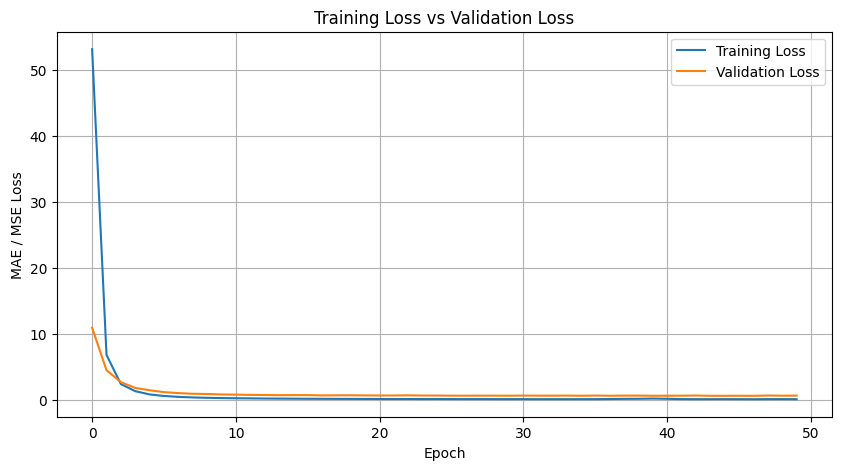

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('MAE / MSE Loss')
plt.title('Training Loss vs Validation Loss')

plt.legend()
plt.grid()
plt.show()

In [ ]:
def build_model(params, input_dim):

    model = models.Sequential()

    model.add(layers.Input(shape=(input_dim,)))

    for i in range(params['n_layers']):

        model.add(layers.Dense(
            params[f'units_{i}'],
            activation=params['activation'],
            kernel_initializer='he_normal' if params['activation'] == 'relu' else 'glorot_uniform',
            kernel_regularizer=regularizers.l2(params['l2'])
        ))

        if params['dropout'] > 0:
            model.add(layers.Dropout(params['dropout']))

    model.add(layers.Dense(1, activation='linear'))

    if params['optimizer'] == 'adam':
        optimizer = tf.keras.optimizers.Adam(
            learning_rate=params['learning_rate']
        )
    else:
        optimizer = tf.keras.optimizers.RMSprop(
            learning_rate=params['learning_rate']
        )

    model.compile(
        optimizer=optimizer,
        loss='mse',
        metrics=['mae']
    )

    return model

In [ ]:
def objective(trial):

    params = {
        'n_layers': trial.suggest_int('n_layers', 1, 4),

        'activation': trial.suggest_categorical(
            'activation', ['relu', 'tanh']
        ),

        'learning_rate': trial.suggest_float(
            'learning_rate', 1e-5, 1e-2, log=True
        ),

        'dropout': trial.suggest_float(
            'dropout', 0.0, 0.5
        ),

        'l2': trial.suggest_float(
            'l2', 1e-7, 1e-2, log=True
        ),

        'optimizer': trial.suggest_categorical(
            'optimizer', ['adam', 'rmsprop']
        )
    }

    # Tune neurons in each hidden layer
    for i in range(params['n_layers']):
        params[f'units_{i}'] = trial.suggest_categorical(
            f'units_{i}', [16, 32, 64, 128, 256]
        )

    batch_size = trial.suggest_categorical(
        'batch_size', [16, 32, 64, 128]
    )

    # Create a fresh model for every trial
    tf.keras.backend.clear_session()

    model = build_model(
        params,
        input_dim=x_train.shape[1]
    )

    early_stop = EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True
    )

    model.fit(
        x_train,
        y_train,
        epochs=150,
        batch_size=batch_size,
        validation_data=(x_val, y_val),
        callbacks=[early_stop],
        verbose=0
    )

    y_pred = model.predict(x_val, verbose=0).flatten()

    score = r2_score(y_val, y_pred)

    return score

In [ ]:
study = optuna.create_study(
    direction='maximize'
)

study.optimize(
    objective,
    n_trials=50
)

[I 2026-11-02 11:02:22,426] A new study created in memory with name: no-name-720194d4-4943-45b4-a92b-6dc42a2f6d80
[I 2026-11-02 11:03:02,880] Trial 0 finished with value: -8.283974130002912 and parameters: {'n_layers': 3, 'activation': 'tanh', 'learning_rate': 5.733982154418931e-05, 'dropout': 0.23298609588662206, 'l2': 0.00488216733147271, 'optimizer': 'rmsprop', 'units_0': 16, 'units_1': 32, 'units_2': 64, 'batch_size': 128}. Best is trial 0 with value: -8.283974130002912.
[I 2026-11-02 11:04:03,784] Trial 1 finished with value: -1.001109086467319 and parameters: {'n_layers': 2, 'activation': 'tanh', 'learning_rate': 0.001731990551410404, 'dropout': 0.015363811435946673, 'l2': 4.499722290928844e-06, 'optimizer': 'adam', 'units_0': 32, 'units_1': 32, 'batch_size': 16}. Best is trial 1 with value: -1.001109086467319.
[I 2026-11-02 11:04:15,406] Trial 2 finished with value: -2.496773201191136 and parameters: {'n_layers': 3, 'activation': 'relu', 'learning_rate': 0.000652843153716193, 'd

In [ ]:
print("Best R2 Score:", study.best_value)
print("Best Parameters:", study.best_params)

Best R2 Score: 0.7348167841081013
Best Parameters: {'n_layers': 3, 'activation': 'relu', 'learning_rate': 0.0023248804443525236, 'dropout': 0.1342651008608014, 'l2': 0.00025557998056597957, 'optimizer': 'adam', 'units_0': 32, 'units_1': 32, 'units_2': 256, 'batch_size': 32}


In [ ]:
model = models.Sequential()

model.add(layers.Input(shape=(x_train.shape[1],)))

model.add(layers.Dense(32, activation='relu', kernel_initializer='he_normal', kernel_regularizer=regularizers.l2(0.00025557998056597957)))
model.add(layers.Dropout(0.1342651008608014))
model.add(layers.Dense(32, activation='relu', kernel_initializer='he_normal', kernel_regularizer=regularizers.l2(0.00025557998056597957)))
model.add(layers.Dropout(0.1342651008608014))
model.add(layers.Dense(256, activation='relu', kernel_initializer='he_normal', kernel_regularizer=regularizers.l2(0.00025557998056597957)))
model.add(layers.Dropout(0.1342651008608014))
model.add(layers.Dense(1, activation='linear'))

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae']
)

In [ ]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 32)             │         1,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │         8,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,073 (43.25 KB)

 Trainable params: 11,073 (43.25 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
early_stop = EarlyStopping(
      monitor='val_loss',
      patience=10,
      restore_best_weights=True
  )

history = model.fit(
    x = x_train,
    y = y_train,
    batch_size=32,
    epochs=150,
    validation_data=(x_val, y_val),
    callbacks=[early_stop],
)

Epoch 1/150
58/58 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.3634 - mae: 0.4270 - val_loss: 0.3219 - val_mae: 0.3973
Epoch 2/150
58/58 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.3588 - mae: 0.4284 - val_loss: 0.3128 - val_mae: 0.3857
Epoch 3/150
58/58 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - loss: 0.3727 - mae: 0.4345 - val_loss: 0.2968 - val_mae: 0.3611
Epoch 4/150
58/58 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.3572 - mae: 0.4270 - val_loss: 0.3011 - val_mae: 0.3697
Epoch 5/150
58/58 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - loss: 0.3425 - mae: 0.4162 - val_loss: 0.3200 - val_mae: 0.3911
Epoch 6/150
58/58 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.3555 - mae: 0.4254 - val_loss: 0.2881 - val_mae: 0.3528
Epoch 7/150
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.3481 - mae: 0.4179 - val_loss: 0.3006 - val_mae: 0.3728
Epoch 8/150
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.3379 - mae: 0.4148 - val_loss: 0.2955 - val_mae: 0.3727
Epoch 9/150
58/58 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss:

In [ ]:
y_pred = model.predict(x_test).flatten()
y_test_original = np.exp(y_test)
y_pred_original = np.exp(y_pred)

print("MAE", mean_absolute_error(y_test_original, y_pred_original))
print('R2_Score', r2_score( y_test_original, y_pred_original))


print("\n" + "=" * 40 + "\n")

print("Without exp (Log Scale)")
print("MAE:", mean_absolute_error(y_test, y_pred))
print("R2_Score:", r2_score(y_test, y_pred))

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
MAE 10058.23496325263
R2_Score 0.530314260098111


Without exp (Log Scale)
MAE: 0.3894551250484285
R2_Score: 0.6246491495330176


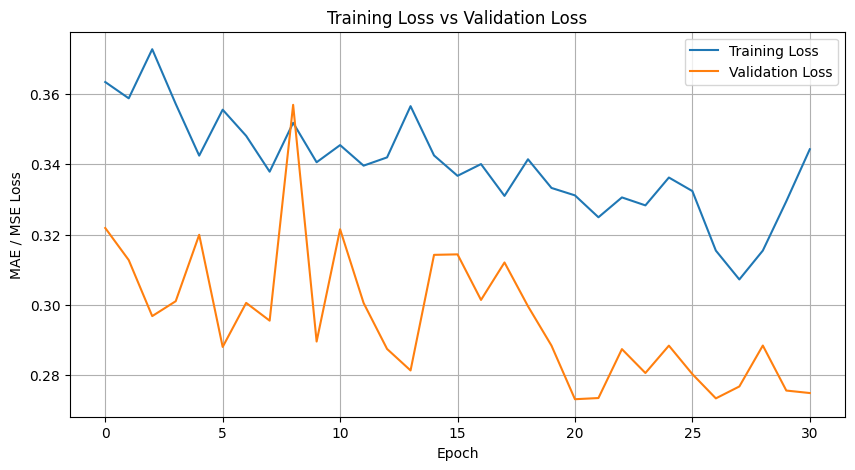

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('MAE / MSE Loss')
plt.title('Training Loss vs Validation Loss')

plt.legend()
plt.grid()
plt.show()

In [ ]:
def build_model(params, input_dim):

    model = models.Sequential()

    model.add(layers.Input(shape=(input_dim,)))

    for i in range(params['n_layers']):
        if params[f'kernel_regularizer_{i}'] == 'l1':
            kernel_reg = regularizers.l1(params[f'l1_{i}'])
        else:
            kernel_reg = regularizers.l2(params[f'l2_{i}'])

        model.add(layers.Dense(
            params[f'units_{i}'],
            activation=params['activation'],
            kernel_initializer='he_normal' if params['activation'] == 'relu' else 'glorot_uniform',
            kernel_regularizer=kernel_reg
        ))
        model.add(layers.Dropout(params[f'dropout_{i}']))

    model.add(layers.Dense(1, activation='linear'))

    if params['optimizer'] == 'adam':
        optimizer = tf.keras.optimizers.Adam(
            learning_rate=params['learning_rate']
        )
    else:
        optimizer = tf.keras.optimizers.RMSprop(
            learning_rate=params['learning_rate']
        )

    model.compile(
        optimizer=optimizer,
        loss='mse',
        metrics=['mae']
    )

    return model

In [ ]:
def objective(trial):

    params = {
        'n_layers': trial.suggest_int('n_layers', 1, 4),

        'activation': trial.suggest_categorical(
            'activation', ['relu', 'tanh']
        ),

        'learning_rate': trial.suggest_float(
            'learning_rate', 1e-5, 1e-2, log=True
        ),

        'optimizer': trial.suggest_categorical(
            'optimizer', ['adam', 'rmsprop']
        )
    }

    # Tune neurons in each hidden layer
    for i in range(params['n_layers']):
        params[f'units_{i}'] = trial.suggest_categorical(
            f'units_{i}', [16, 32, 64, 128, 256]
        )

        params[f'dropout_{i}'] = trial.suggest_float(
            f'dropout_{i}', 0.0, 0.5
        )

        params[f'kernel_regularizer_{i}'] = trial.suggest_categorical(
            f'kernel_regularizer_{i}', ['l1', 'l2']
        )

        if params[f'kernel_regularizer_{i}'] == 'l1':

            params[f'l1_{i}'] = trial.suggest_float(
                f'l1_{i}', 1e-7, 1e-1, log=True
            )

        else:

            params[f'l2_{i}'] = trial.suggest_float(
                f'l2_{i}', 1e-7, 1e-2, log=True
            )


    batch_size = trial.suggest_categorical(
        'batch_size', [16, 32, 64, 128]
    )

    # Create a fresh model for every trial
    tf.keras.backend.clear_session()

    model = build_model(
        params,
        input_dim=x_train.shape[1]
    )

    early_stop = EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True
    )

    model.fit(
        x_train,
        y_train,
        epochs=150,
        batch_size=batch_size,
        validation_data=(x_val, y_val),
        callbacks=[early_stop],
        verbose=0
    )

    y_pred = model.predict(x_val, verbose=0).flatten()

    score = r2_score(y_val, y_pred)

    return score

In [ ]:
study = optuna.create_study(
    direction='maximize'
)

study.optimize(
    objective,
    n_trials=70
)

[I 2026-11-03 04:12:56,686] A new study created in memory with name: no-name-fa75dea9-537e-4d9f-91d3-39d0200fdef1
[I 2026-11-03 04:13:10,529] Trial 0 finished with value: -5.158372783333046 and parameters: {'n_layers': 2, 'activation': 'relu', 'learning_rate': 0.006529432933434055, 'optimizer': 'rmsprop', 'units_0': 64, 'dropout_0': 0.0719672318834283, 'kernel_regularizer_0': 'l1', 'l1_0': 4.413164667736953e-07, 'units_1': 256, 'dropout_1': 0.37179953633753926, 'kernel_regularizer_1': 'l2', 'l2_1': 5.828644049813852e-05, 'batch_size': 32}. Best is trial 0 with value: -5.158372783333046.
[I 2026-11-03 04:13:43,333] Trial 1 finished with value: 0.6067789520022173 and parameters: {'n_layers': 4, 'activation': 'relu', 'learning_rate': 0.002097689431568752, 'optimizer': 'rmsprop', 'units_0': 128, 'dropout_0': 0.39226411636097114, 'kernel_regularizer_0': 'l1', 'l1_0': 0.05980404910612832, 'units_1': 256, 'dropout_1': 0.32346856236818317, 'kernel_regularizer_1': 'l1', 'l1_1': 0.00363129419277

In [ ]:
print("Best R2 Score:", study.best_value)
print("Best Parameters:", study.best_params)

Best R2 Score: 0.7412875495918325
Best Parameters: {'n_layers': 3, 'activation': 'relu', 'learning_rate': 0.0022711422270949837, 'optimizer': 'adam', 'units_0': 128, 'dropout_0': 0.3515312112125227, 'kernel_regularizer_0': 'l2', 'l2_0': 2.1775135854041282e-07, 'units_1': 128, 'dropout_1': 0.49820702800521866, 'kernel_regularizer_1': 'l2', 'l2_1': 0.005780122443693118, 'units_2': 64, 'dropout_2': 0.19925159830725878, 'kernel_regularizer_2': 'l2', 'l2_2': 0.004252251503496007, 'batch_size': 16}


In [ ]:
model = models.Sequential()

model.add(layers.Input(shape=(x_train.shape[1],)))

model.add(layers.Dense(128, activation='relu', kernel_initializer='he_normal', kernel_regularizer=regularizers.l2(2.1775135854041282e-07)))
model.add(layers.Dropout(0.3515312112125227))
model.add(layers.Dense(128, activation='relu', kernel_initializer='he_normal', kernel_regularizer=regularizers.l2(0.005780122443693118)))
model.add(layers.Dropout(0.49820702800521866))
model.add(layers.Dense(64, activation='relu', kernel_initializer='he_normal', kernel_regularizer=regularizers.l2(0.004252251503496007)))
model.add(layers.Dropout(0.19925159830725878))
model.add(layers.Dense(1, activation='linear'))

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0022711422270949837),
    loss='mse',
    metrics=['mae']
)

In [ ]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 32)             │         1,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │         8,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,073 (43.25 KB)

 Trainable params: 11,073 (43.25 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
early_stop = EarlyStopping(
      monitor='val_loss',
      patience=10,
      restore_best_weights=True
  )

history = model.fit(
    x = x_train,
    y = y_train,
    batch_size=32,
    epochs=100,
    validation_data=(x_val, y_val),
    callbacks=[early_stop],
)

Epoch 1/100
58/58 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.2205 - mae: 0.3477 - val_loss: 0.2530 - val_mae: 0.3688
Epoch 2/100
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.2065 - mae: 0.3346 - val_loss: 0.2389 - val_mae: 0.3522
Epoch 3/100
58/58 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.2166 - mae: 0.3454 - val_loss: 0.2569 - val_mae: 0.3658
Epoch 4/100
58/58 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.2078 - mae: 0.3399 - val_loss: 0.2483 - val_mae: 0.3647
Epoch 5/100
58/58 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.2146 - mae: 0.3455 - val_loss: 0.2422 - val_mae: 0.3540
Epoch 6/100
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.2165 - mae: 0.3419 - val_loss: 0.2423 - val_mae: 0.3530
Epoch 7/100
58/58 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.2085 - mae: 0.3372 - val_loss: 0.2468 - val_mae: 0.3541
Epoch 8/100
58/58 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.2076 - mae: 0.3341 - val_loss: 0.2373 - val_mae: 0.3549
Epoch 9/100
58/58 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 

In [ ]:
y_pred = model.predict(x_test).flatten()
y_test_original = np.exp(y_test)
y_pred_original = np.exp(y_pred)

print("MAE", mean_absolute_error(y_test_original, y_pred_original))
print('R2_Score', r2_score( y_test_original, y_pred_original))


print("\n" + "=" * 40 + "\n")

print("Without exp (Log Scale)")
print("MAE:", mean_absolute_error(y_test, y_pred))
print("R2_Score:", r2_score(y_test, y_pred))

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
MAE 10110.370383427064
R2_Score 0.5423185121412354


Without exp (Log Scale)
MAE: 0.3855858359388559
R2_Score: 0.6405909318103711


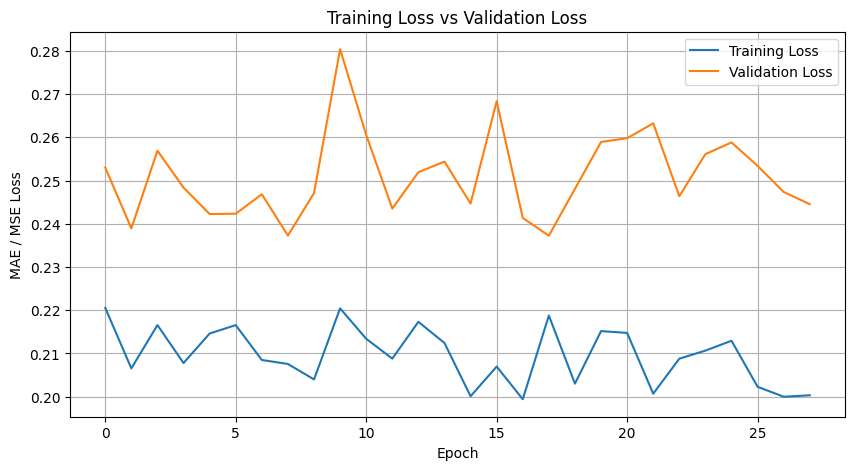

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('MAE / MSE Loss')
plt.title('Training Loss vs Validation Loss')

plt.legend()
plt.grid()
plt.show()

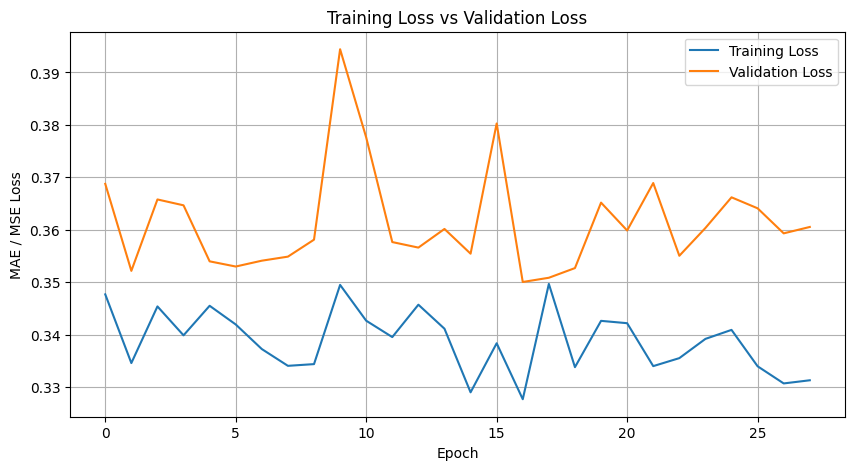

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(history.history['mae'], label='Training Loss')
plt.plot(history.history['val_mae'], label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('MAE / MSE Loss')
plt.title('Training Loss vs Validation Loss')

plt.legend()
plt.grid()
plt.show()